# Project 15 — Replicating "Lazy Prices" on the S&P 100
Cohen, Malloy and Nguyen (2020, *Journal of Finance*) find that firms whose annual reports change a lot from the prior
year ("changers") underperform firms that barely change them. This notebook tests the result on the current S&P 100,
fiscal years 2012–2025, using Item 1A (Risk Factors) and Item 7 (MD&A) of each original 10-K.

Inputs (built by the scripts in `src/`, see README):
- `data/text_features.csv` — one row per firm and fiscal year: section source, cosine similarities to the prior year
  (Item 1A, Item 7, combined) and Loughran-McDonald word shares (`src/build_sections.py`).
- `data/finbert_mda.csv` — mean P(positive) − P(negative) over all MD&A sentences (`src/finbert.py`).
- `data/returns_monthly.csv`, `data/market_cap_monthly.csv` — yfinance and SEC XBRL (`src/market.py`).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd
import statsmodels.api as sm

from common import data as D
from common.plotting import PALETTE, setup, source

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SRC = "Source: SEC EDGAR 10-K filings (edgartools), yfinance, Kenneth French Data Library; author's calculations."
START, END = "2014-01", "2026-09"            # portfolio months (returns)

## 1. Text features and the sample

In [2]:
F = pd.read_csv(DATA / "text_features.csv", parse_dates=["filed"]).sort_values(["ticker", "fy"])
FB = pd.read_csv(DATA / "finbert_mda.csv")
F = F.merge(FB[["ticker", "fy", "finbert_mda"]], on=["ticker", "fy"], how="left")
F.loc[F["src_7"] == "missing", "finbert_mda"] = np.nan
F["d_finbert"] = F.groupby("ticker")["finbert_mda"].diff().where(F.groupby("ticker")["fy"].diff() == 1)

# A similarity is usable only if both sections were extracted from the 10-K itself (not an Exhibit 13 annual
# report extract) in both years, from the same extraction route, for consecutive fiscal years.
ok = F["src_1a"].isin(["10-K item", "10-K regex"]) & F["src_7"].isin(["10-K item", "10-K regex"])
F["valid"] = ok & ok.groupby(F["ticker"]).shift().fillna(False).astype(bool) & (F.groupby("ticker")["fy"].diff() == 1) & ~F["src_change"]
cov = pd.DataFrame({"10-Ks (original filings)": F[F["fy"] >= 2012].groupby("fy").size(),
                    "Usable similarity pairs": F[F["valid"]].groupby("fy").size()}).fillna(0).astype(int)
SRC_COUNTS = F[F["fy"] >= 2012][["src_1a", "src_7"]].apply(pd.Series.value_counts).fillna(0).astype(int)
print(f"{F[F['fy'] >= 2012]['ticker'].nunique()} firms, {len(F[F['fy'] >= 2012])} firm-years FY2012–2025, "
      f"{int(F['valid'].sum())} usable similarity pairs from {F[F['valid']]['ticker'].nunique()} firms")
cov.T, SRC_COUNTS

100 firms, 1313 firm-years FY2012–2025, 1067 usable similarity pairs from 94 firms


(fy                        2012  2013  2014  2015  2016  2017  2018  2019  \
 10-Ks (original filings)    88    88    88    90    91    92    94    96   
 Usable similarity pairs     55    64    62    67    72    70    72    78   
 
 fy                        2020  2021  2022  2023  2024  2025  
 10-Ks (original filings)    96    97    97    97    99   100  
 Usable similarity pairs     82    86    88    89    90    92  ,
                      src_1a  src_7
 10-K item              1252   1113
 10-K regex                2      9
 exhibit 13               42     78
 exhibit 13 (capped)       0      3
 missing                  17    110)

In [3]:
V = F[F["valid"]].copy()
DESC = V[["sim_1a", "sim_7", "sim_combined", "lm_negative", "lm_uncertainty", "lm_litigious", "d_lm_negative", "finbert_mda"]].describe(
    percentiles=[0.01, 0.5, 0.99]).T
CORR = V[["sim_1a", "sim_7", "sim_combined", "d_lm_negative", "d_lm_uncertainty", "finbert_mda", "d_finbert"]].corr(method="spearman")
DESC.round(4), CORR.round(2)

(                 count    mean     std     min      1%     50%     99%     max
 sim_1a          1067.0  0.9782  0.0445  0.4146  0.7935  0.9885  0.9993  1.0000
 sim_7           1067.0  0.9700  0.0223  0.8048  0.8893  0.9767  0.9952  0.9977
 sim_combined    1067.0  0.9789  0.0193  0.7922  0.9106  0.9845  0.9972  0.9990
 lm_negative     1067.0  0.0259  0.0056  0.0114  0.0130  0.0255  0.0386  0.0415
 lm_uncertainty  1067.0  0.0224  0.0042  0.0102  0.0124  0.0225  0.0312  0.0324
 lm_litigious    1067.0  0.0114  0.0037  0.0033  0.0045  0.0108  0.0203  0.0399
 d_lm_negative   1067.0  0.0006  0.0016 -0.0055 -0.0034  0.0005  0.0050  0.0087
 finbert_mda     1067.0  0.0470  0.0705 -0.2806 -0.1271  0.0454  0.2098  0.2631,
                   sim_1a  sim_7  sim_combined  d_lm_negative  \
 sim_1a              1.00   0.29          0.63          -0.12   
 sim_7               0.29   1.00          0.81          -0.14   
 sim_combined        0.63   0.81          1.00          -0.15   
 d_lm_negative     

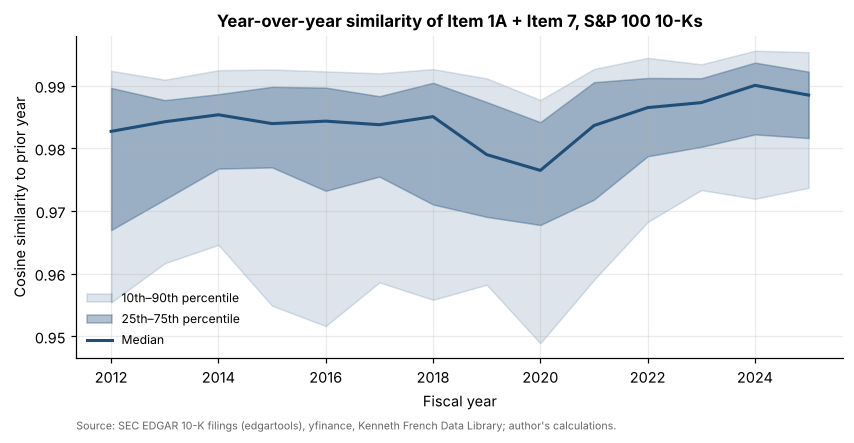

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
q = V.groupby("fy")["sim_combined"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack()
ax.fill_between(q.index, q[0.1], q[0.9], color=PALETTE[0], alpha=0.15, label="10th–90th percentile")
ax.fill_between(q.index, q[0.25], q[0.75], color=PALETTE[0], alpha=0.35, label="25th–75th percentile")
ax.plot(q.index, q[0.5], color=PALETTE[0], lw=2, label="Median")
ax.set_ylabel("Cosine similarity to prior year"); ax.set_xlabel("Fiscal year")
ax.set_title("Year-over-year similarity of Item 1A + Item 7, S&P 100 10-Ks")
ax.legend(fontsize=8, loc="lower left"); source(ax, SRC)
fig.savefig(FIG / "fig_similarity_by_year.png"); plt.show()

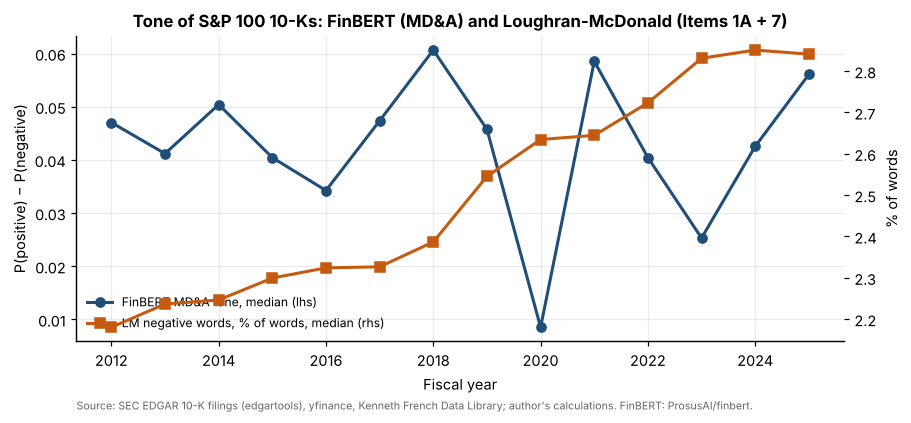

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
tone = F[(F["fy"] >= 2012) & F["finbert_mda"].notna()].groupby("fy")[["finbert_mda", "lm_negative"]].median()
ax.plot(tone.index, tone["finbert_mda"], color=PALETTE[0], lw=2, marker="o", label="FinBERT MD&A tone, median (lhs)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(tone.index, tone["lm_negative"] * 100, color=PALETTE[1], lw=2, marker="s", label="LM negative words, % of words, median (rhs)")
ax.set_xlabel("Fiscal year"); ax.set_ylabel("P(positive) − P(negative)"); ax2.set_ylabel("% of words")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower left")
ax.set_title("Tone of S&P 100 10-Ks: FinBERT (MD&A) and Loughran-McDonald (Items 1A + 7)")
source(ax, SRC + " FinBERT: ProsusAI/finbert.")
fig.savefig(FIG / "fig_tone_by_year.png"); plt.show()

## 2. Monthly panel
At each month-end *t* every firm carries its most recent usable 10-K signal filed on or before *t* (and no more
than 15 months old). The return earned is the firm's total return in month *t+1*.

In [6]:
R = pd.read_csv(DATA / "returns_monthly.csv", index_col=0, parse_dates=True)
MC = pd.read_csv(DATA / "market_cap_monthly.csv", index_col=0, parse_dates=True)
R.columns = [c.replace("-", ".") for c in R.columns]; MC.columns = [c.replace("-", ".") for c in MC.columns]
months = pd.date_range("2013-12-31", "2026-08-31", freq="ME")        # formation dates; returns Jan 2014 – Sep 2026
SIG = ["sim_combined", "sim_1a", "sim_7", "d_lm_negative", "d_lm_uncertainty", "d_lm_litigious", "finbert_mda", "d_finbert"]
sig = F.loc[F["valid"] | F["finbert_mda"].notna(), ["ticker", "fy", "filed", "valid"] + SIG].copy()
for c in ["sim_combined", "sim_1a", "sim_7"]:
    sig.loc[~sig["valid"], c] = np.nan
sig = sig.sort_values("filed")

# momentum 12-1 and prior-month return from the same return file
cum = (1 + R).rolling(11).apply(np.prod, raw=True) - 1                 # months t-11 .. t-1 after the shift below
MOM = cum.shift(1)
rows = []
for t in months:
    s = sig[(sig["filed"] <= t) & (sig["filed"] > t - pd.DateOffset(months=15))].groupby("ticker").last()
    nxt = t + pd.offsets.MonthEnd(1)
    for tk, r in s.iterrows():
        if tk not in R.columns or nxt not in R.index or pd.isna(R.at[nxt, tk]):
            continue
        rows.append({"date": t, "ticker": tk, **{c: r[c] for c in SIG}, "fy": r["fy"], "filed": r["filed"],
                     "ret_next": R.at[nxt, tk], "ret_prev": R.at[t, tk] if t in R.index else np.nan,
                     "mom_12_1": MOM.at[t, tk] if t in MOM.index else np.nan,
                     "log_mcap": np.log(MC.at[t, tk]) if (tk in MC.columns and t in MC.index and MC.at[t, tk] > 0) else np.nan,
                     "mcap": MC.at[t, tk] if (tk in MC.columns and t in MC.index) else np.nan})
P = pd.DataFrame(rows)
print(P.groupby("date")["sim_combined"].count().describe().round(1))
P.head()

count    153.0
mean      77.6
std        9.9
min       58.0
25%       71.0
50%       78.0
75%       88.0
max       93.0
Name: sim_combined, dtype: float64


,date,ticker,sim_combined,sim_1a,sim_7,d_lm_negative,d_lm_uncertainty,d_lm_litigious,finbert_mda,d_finbert,fy,filed,ret_next,ret_prev,mom_12_1,log_mcap,mcap
0,2013-12-31,AAPL,0.985468,0.996999,0.962143,0.001216,-0.000598,-0.000265,0.040760,-0.114398,2013,2013-10-30,-0.107697,0.008902,0.071161,26.947371,5.047710e+11
1,2013-12-31,ABBV,NaN,NaN,NaN,NaN,NaN,NaN,0.066060,NaN,2012,2013-03-15,-0.060406,0.089989,NaN,25.154242,8.401341e+10
2,2013-12-31,ABT,0.973959,0.967068,0.970220,0.002076,0.000374,-0.000659,0.110280,0.008555,2012,2013-02-15,-0.038222,0.003666,0.235039,24.805290,5.926530e+10
3,2013-12-31,ACN,NaN,NaN,NaN,0.000613,-0.000632,0.000146,0.036391,-0.044700,2013,2013-10-29,-0.028460,0.061314,0.193085,24.681201,5.234911e+10
4,2013-12-31,ADBE,0.987315,0.994039,0.981771,0.000047,0.000301,-0.000015,0.011511,-0.016193,2012,2013-01-22,-0.011523,0.054597,0.506900,24.122236,2.993325e+10


## 3. Portfolio test: long the most similar quintile (non-changers), short the least similar (changers)

In [7]:
def quintile_returns(P, col, weight=None):
    out = {}
    for t, g in P.dropna(subset=[col]).groupby("date"):
        if len(g) < 25:
            continue
        q = pd.qcut(g[col].rank(method="first"), 5, labels=False) + 1
        if weight is None:
            out[t + pd.offsets.MonthEnd(1)] = g.groupby(q)["ret_next"].mean()
        else:
            w = g[weight]
            ok_ = w.notna()
            out[t + pd.offsets.MonthEnd(1)] = (g.loc[ok_, "ret_next"] * w[ok_]).groupby(q[ok_]).sum() / w[ok_].groupby(q[ok_]).sum()
    Q = pd.DataFrame(out).T
    Q.columns = [f"Q{int(c)}" for c in Q.columns]
    Q["Q5-Q1"] = Q["Q5"] - Q["Q1"]
    return Q


ff = D.french("F-F_Research_Data_5_Factors_2x3", DATA / "ff5_monthly.csv")
mom = D.french("F-F_Momentum_Factor", DATA / "ff_momentum_monthly.csv")
FF = ff.join(mom); FF.columns = [c.strip() for c in FF.columns]
FAC = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]


def stats(x, rf=None, factors=True):
    x = x.dropna()
    m = sm.OLS(x, np.ones(len(x))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    out = {"Mean (monthly)": x.mean(), "t(mean)": m.tvalues.iloc[0], "Ann. return": (1 + x).prod() ** (12 / len(x)) - 1,
           "Ann. vol": x.std() * np.sqrt(12), "Sharpe (ann.)": x.mean() / x.std() * np.sqrt(12), "Months": len(x)}
    if factors:
        d = pd.concat([x.rename("y"), FF[FAC]], axis=1, sort=True).dropna()
        a = sm.OLS(d["y"], sm.add_constant(d[FAC])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        out.update({"Alpha FF5+Mom (monthly)": a.params["const"], "t(alpha)": a.tvalues["const"],
                    "Alpha (ann.)": a.params["const"] * 12, **{f"b_{f}": a.params[f] for f in FAC}, "Alpha months": len(d),
                    "R2": a.rsquared})
    return out


Q = {k: quintile_returns(P, k) for k in ["sim_combined", "sim_1a", "sim_7"]}
QVW = quintile_returns(P, "sim_combined", weight="mcap")
QS = Q["sim_combined"].loc[START:END]
MAIN = stats(QS["Q5-Q1"])
pd.Series(MAIN).round(4)

Mean (monthly)               0.0029
t(mean)                      1.2620
Ann. return                  0.0312
Ann. vol                     0.0954
Sharpe (ann.)                0.3696
Months                     153.0000
Alpha FF5+Mom (monthly)      0.0020
t(alpha)                     0.8399
Alpha (ann.)                 0.0238
b_Mkt-RF                     0.1004
b_SMB                       -0.0889
b_HML                        0.0611
b_RMW                       -0.2360
b_CMA                       -0.2833
b_Mom                       -0.0653
Alpha months               152.0000
R2                           0.1408
dtype: float64

In [8]:
QTAB = pd.DataFrame({c: stats(QS[c] - FF["RF"].reindex(QS.index), factors=True) for c in ["Q1", "Q2", "Q3", "Q4", "Q5"]}).T
QTAB.loc["Q5-Q1"] = pd.Series(MAIN)
QTAB[["Mean (monthly)", "t(mean)", "Alpha FF5+Mom (monthly)", "t(alpha)", "Sharpe (ann.)"]].round(4)

,Mean (monthly),t(mean),Alpha FF5+Mom (monthly),t(alpha),Sharpe (ann.)
Q1,0.0130,4.8476,0.0034,2.1829,0.9963
Q2,0.0142,4.5377,0.0039,2.1959,1.0312
Q3,0.0161,6.3527,0.0063,5.6007,1.2724
Q4,0.0152,5.6565,0.0061,4.7169,1.2011
Q5,0.0158,4.5882,0.0053,4.0356,1.1022
Q5-Q1,0.0029,1.2620,0.0020,0.8399,0.3696


In [9]:
ROB = {}
for k in ["sim_combined", "sim_1a", "sim_7"]:
    ROB[f"{k} · equal-weight"] = stats(Q[k].loc[START:END, "Q5-Q1"])
ROB["sim_combined · value-weight"] = stats(QVW.loc[START:END, "Q5-Q1"])
ROB["sim_combined · 2014–2019"] = stats(QS.loc["2014":"2019", "Q5-Q1"])
ROB["sim_combined · 2020–2026"] = stats(QS.loc["2020":END, "Q5-Q1"])
# terciles instead of quintiles (about 30 stocks per leg)
def tercile_ls(P, col):
    out = {}
    for t, g in P.dropna(subset=[col]).groupby("date"):
        q = pd.qcut(g[col].rank(method="first"), 3, labels=False)
        out[t + pd.offsets.MonthEnd(1)] = g.loc[q == 2, "ret_next"].mean() - g.loc[q == 0, "ret_next"].mean()
    return pd.Series(out)
ROB["sim_combined · terciles"] = stats(tercile_ls(P, "sim_combined").loc[START:END])
# sector-adjusted: similarity minus the median of its GICS sector (Wikipedia list) at each formation date
_sec = pd.read_csv(DATA / "sp100_constituents_wikipedia.csv").assign(ticker=lambda d: d["Symbol"].str.replace("-", "."))
P["sector"] = P["ticker"].map(_sec.drop_duplicates("ticker").set_index("ticker")["Sector"])
P["sim_sector_adj"] = P["sim_combined"] - P.groupby(["date", "sector"])["sim_combined"].transform("median")
ROB["sim_combined · sector-adjusted"] = stats(quintile_returns(P, "sim_sector_adj").loc[START:END, "Q5-Q1"])
ROBT = pd.DataFrame(ROB).T
ROBT[["Mean (monthly)", "t(mean)", "Sharpe (ann.)", "Alpha FF5+Mom (monthly)", "t(alpha)", "Months"]].round(4)

,Mean (monthly),t(mean),Sharpe (ann.),Alpha FF5+Mom (monthly),t(alpha),Months
sim_combined · equal-weight,0.0029,1.2620,0.3696,0.0020,0.8399,153.0
sim_1a · equal-weight,0.0029,1.4660,0.3676,0.0017,0.8760,153.0
sim_7 · equal-weight,-0.0014,-0.4411,-0.1523,0.0005,0.1677,153.0
sim_combined · value-weight,-0.0034,-1.1430,-0.3379,-0.0033,-1.2317,153.0
sim_combined · 2014–2019,0.0031,1.2106,0.4421,0.0029,1.1222,72.0
sim_combined · 2020–2026,0.0028,0.7435,0.3215,0.0017,0.4502,81.0
sim_combined · terciles,0.0007,0.3750,0.1046,0.0008,0.4491,153.0
sim_combined · sector-adjusted,0.0029,1.1774,0.3529,0.0026,1.2149,153.0


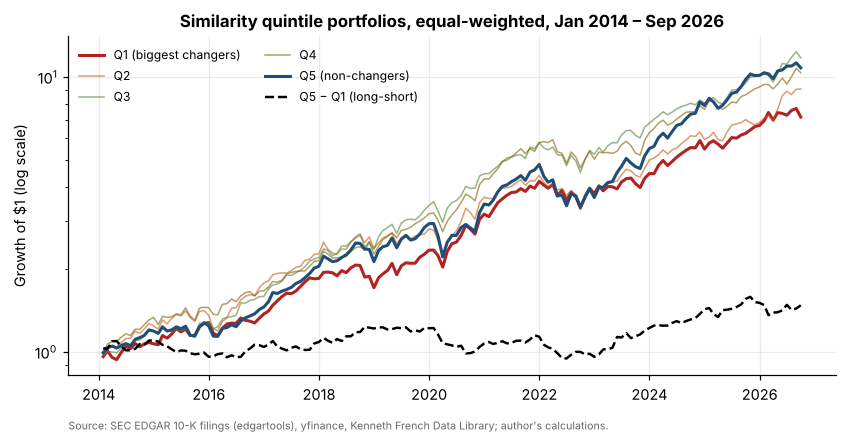

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
for i, c in enumerate(["Q1", "Q2", "Q3", "Q4", "Q5"]):
    ax.plot((1 + QS[c]).cumprod(), color=PALETTE[i] if c not in ("Q1", "Q5") else ("#B22222" if c == "Q1" else "#1F4E79"),
            lw=2 if c in ("Q1", "Q5") else 1, alpha=1 if c in ("Q1", "Q5") else 0.6,
            label={"Q1": "Q1 (biggest changers)", "Q5": "Q5 (non-changers)"}.get(c, c))
ax.plot((1 + QS["Q5-Q1"]).cumprod(), color="black", lw=1.6, ls="--", label="Q5 − Q1 (long-short)")
ax.set_yscale("log"); ax.set_ylabel("Growth of $1 (log scale)")
ax.set_title("Similarity quintile portfolios, equal-weighted, Jan 2014 – Sep 2026")
ax.legend(fontsize=8, ncol=2); source(ax, SRC)
fig.savefig(FIG / "fig_quintile_growth.png"); plt.show()

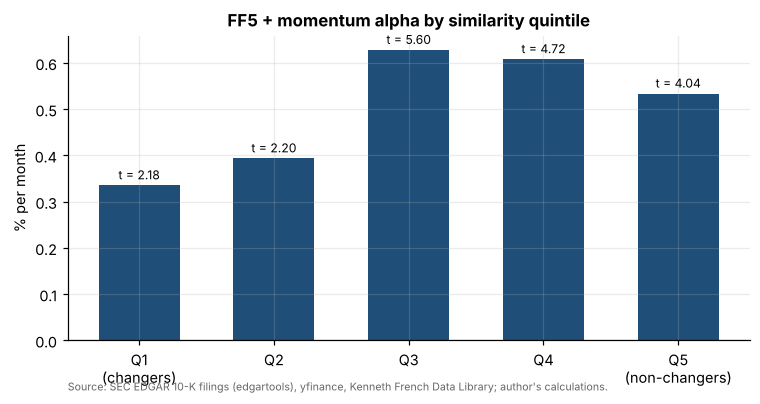

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(5)
ax.bar(x, QTAB.loc[["Q1", "Q2", "Q3", "Q4", "Q5"], "Alpha FF5+Mom (monthly)"] * 100, color=PALETTE[0], width=0.6)
for i, (a, t) in enumerate(QTAB.loc[["Q1", "Q2", "Q3", "Q4", "Q5"], ["Alpha FF5+Mom (monthly)", "t(alpha)"]].values):
    ax.annotate(f"t = {t:.2f}", (i, a * 100), xytext=(0, 4 if a >= 0 else -12), textcoords="offset points", ha="center", fontsize=8)
ax.axhline(0, color="black", lw=0.7)
ax.set_xticks(x, ["Q1\n(changers)", "Q2", "Q3", "Q4", "Q5\n(non-changers)"]); ax.set_ylabel("% per month")
ax.set_title("FF5 + momentum alpha by similarity quintile")
source(ax, SRC)
fig.savefig(FIG / "fig_quintile_alpha.png"); plt.show()

### Characteristics of the quintiles (as in the paper's Table III) and the spread year by year

In [12]:
SECTOR = pd.read_csv(DATA / "sp100_constituents_wikipedia.csv").assign(ticker=lambda d: d["Symbol"].str.replace("-", "."))
SECTOR = SECTOR.drop_duplicates("ticker").set_index("ticker")["Sector"]
chars = []
for t, g in P.dropna(subset=["sim_combined"]).groupby("date"):
    if len(g) < 25:
        continue
    g = g.assign(q=pd.qcut(g["sim_combined"].rank(method="first"), 5, labels=False) + 1, sector=g["ticker"].map(SECTOR))
    for qq, h in g.groupby("q"):
        chars.append({"date": t, "q": qq, "Firms": len(h), "Market cap ($bn), median": h["mcap"].median() / 1e9,
                      "Similarity (Items 1A + 7)": h["sim_combined"].mean(), "Δ LM negative share (pp)": h["d_lm_negative"].mean() * 100,
                      "FinBERT MD&A tone": h["finbert_mda"].mean(), "Financials share": (h["sector"] == "Financials").mean(),
                      "Health Care share": (h["sector"] == "Health Care").mean(), "IT share": (h["sector"] == "Information Technology").mean()})
CHARS = pd.DataFrame(chars).groupby("q").mean(numeric_only=True).T
CHARS.columns = [f"Q{c}" for c in CHARS.columns]
CHARS.round(3)

,Q1,Q2,Q3,Q4,Q5
Firms,15.915,15.196,15.438,15.196,15.824
"Market cap ($bn), median",108.013,120.059,134.434,133.292,153.233
Similarity (Items 1A + 7),0.951,0.977,0.984,0.988,0.993
Δ LM negative share (pp),0.096,0.064,0.053,0.045,0.032
FinBERT MD&A tone,0.049,0.038,0.056,0.050,0.043
Financials share,0.067,0.063,0.099,0.186,0.248
Health Care share,0.189,0.161,0.199,0.201,0.095
IT share,0.194,0.250,0.233,0.258,0.313


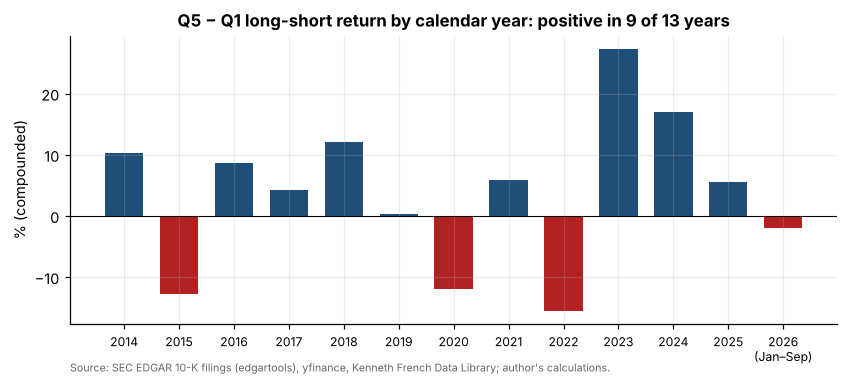

2014    0.1023
2015   -0.1286
2016    0.0863
2017    0.0421
2018    0.1203
2019    0.0022
2020   -0.1204
2021    0.0580
2022   -0.1548
2023    0.2732
2024    0.1694
2025    0.0558
2026   -0.0203
Name: Q5-Q1, dtype: float64

In [13]:
YEARLY = QS["Q5-Q1"].groupby(QS.index.year).apply(lambda x: (1 + x).prod() - 1)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(YEARLY.index, YEARLY * 100, color=[PALETTE[0] if v >= 0 else "#B22222" for v in YEARLY], width=0.7)
ax.axhline(0, color="black", lw=0.7)
ax.set_ylabel("% (compounded)"); ax.set_xticks(YEARLY.index, [str(y) if y < 2026 else "2026\n(Jan–Sep)" for y in YEARLY.index], fontsize=8)
ax.set_title(f"Q5 − Q1 long-short return by calendar year: positive in {int((YEARLY > 0).sum())} of {len(YEARLY)} years")
source(ax, SRC)
fig.savefig(FIG / "fig_yearly_spread.png"); plt.show()
YEARLY.round(4)

### Event time: is there an announcement effect?
The paper finds no reaction when a changed 10-K is filed; returns accrue over the following months. For every usable
filing, abnormal return = stock return − equal-weighted average return of the sample firms that month. Filings are put
into similarity quintiles within their fiscal-year cohort; month 0 is the calendar month of the filing date.

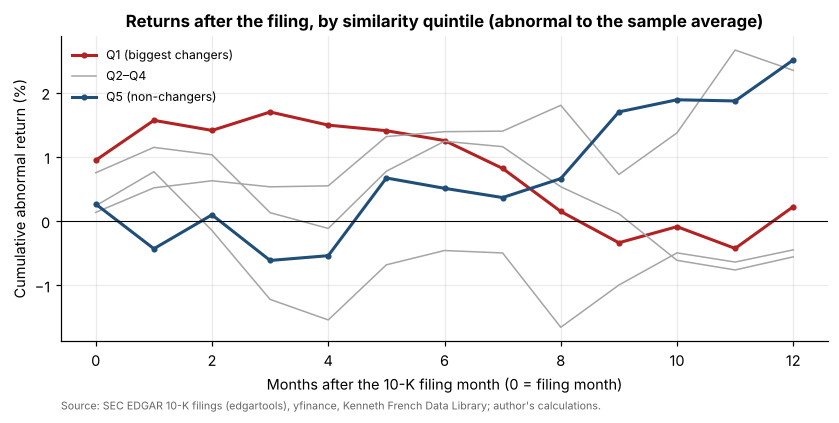

,Q5 (non-changers),Q1 (changers),Q5 − Q1,t,Filings per quintile
Month 0 (filing month),0.0026,0.0095,-0.0068,-0.8759,215.0
Months 1–3,-0.0088,0.0075,-0.0163,-1.2417,215.0
Months 4–6,0.0112,-0.0044,0.0157,1.5138,215.0
Months 7–12,0.0183,-0.0101,0.0284,1.6593,215.0


In [14]:
EW = R.mean(axis=1)
ev = []
VV = V[(V["filed"] >= "2013-01-01")].copy()
VV["q"] = VV.groupby("fy")["sim_combined"].transform(lambda x: pd.qcut(x.rank(method="first"), 5, labels=False) + 1)
for _, row in VV.iterrows():
    tk = row["ticker"]
    if tk not in R.columns:
        continue
    m0 = row["filed"] + pd.offsets.MonthEnd(0)
    for k in range(0, 13):
        m = m0 + pd.offsets.MonthEnd(k)
        if m in R.index and pd.notna(R.at[m, tk]):
            ev.append({"ticker": tk, "fy": row["fy"], "q": row["q"], "k": k, "ar": R.at[m, tk] - EW.at[m]})
EV = pd.DataFrame(ev)
CAR = EV.groupby(["q", "k"])["ar"].mean().unstack(0).cumsum()
WIN = {}
for lab, ks in [("Month 0 (filing month)", [0]), ("Months 1–3", [1, 2, 3]), ("Months 4–6", [4, 5, 6]), ("Months 7–12", list(range(7, 13)))]:
    w = EV[EV["k"].isin(ks)].groupby(["ticker", "fy", "q"])["ar"].sum().reset_index()
    a, b = w.loc[w["q"] == 5, "ar"], w.loc[w["q"] == 1, "ar"]
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    WIN[lab] = {"Q5 (non-changers)": a.mean(), "Q1 (changers)": b.mean(), "Q5 − Q1": diff, "t": diff / se, "Filings per quintile": min(len(a), len(b))}
WINT = pd.DataFrame(WIN).T

fig, ax = plt.subplots(figsize=(9, 3.6))
for qq, c, lw in [(1, "#B22222", 2), (2, PALETTE[7], 1), (3, PALETTE[7], 1), (4, PALETTE[7], 1), (5, "#1F4E79", 2)]:
    ax.plot(CAR.index, CAR[qq] * 100, color=c, lw=lw, marker="o" if qq in (1, 5) else None, ms=3,
            label={1: "Q1 (biggest changers)", 5: "Q5 (non-changers)"}.get(qq, "Q2–Q4" if qq == 2 else None))
ax.axhline(0, color="black", lw=0.7)
ax.set_xlabel("Months after the 10-K filing month (0 = filing month)"); ax.set_ylabel("Cumulative abnormal return (%)")
ax.set_title("Returns after the filing, by similarity quintile (abnormal to the sample average)")
ax.legend(fontsize=8); source(ax, SRC)
fig.savefig(FIG / "fig_event_time.png"); plt.show()
WINT.round(4)

## 4. Fama-MacBeth regressions of next-month return
Each month: cross-sectional OLS of next-month return (in %) on the signals and controls; coefficients are averaged
over months with Newey-West (6 lags) t-statistics. Specification (a) uses raw variables (comparable with the paper's
Table IV); specification (b) standardises every regressor cross-sectionally each month, so each coefficient is the
return per one standard deviation.

In [15]:
def fama_macbeth(P, xs, standardise=False, min_n=30):
    coefs, ns, r2 = [], [], []
    for t, g in P.groupby("date"):
        g = g.dropna(subset=xs + ["ret_next"])
        if len(g) < min_n:
            continue
        X = g[xs].copy()
        if standardise:
            X = (X - X.mean()) / X.std()
        m = sm.OLS(g["ret_next"] * 100, sm.add_constant(X)).fit()
        coefs.append(m.params.rename(t)); ns.append(len(g)); r2.append(m.rsquared_adj)
    C = pd.DataFrame(coefs)
    out = {}
    for c in C.columns:
        mm = sm.OLS(C[c], np.ones(len(C))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        out[c] = (C[c].mean(), mm.tvalues.iloc[0])
    res = pd.DataFrame(out, index=["coef", "t"]).T
    return res, {"months": len(C), "avg N": float(np.mean(ns)), "avg adj. R2": float(np.mean(r2))}


CTRL = ["log_mcap", "mom_12_1", "ret_prev"]
PP = P[(P["date"] >= "2013-12-31")].copy()
SPECS = {"(1) Similarity": ["sim_combined"],
         "(2) + controls": ["sim_combined"] + CTRL,
         "(3) + tone": ["sim_combined", "d_lm_negative", "finbert_mda"] + CTRL,
         "(4) Tone only": ["d_lm_negative", "finbert_mda"] + CTRL}
FM_RAW, FM_STD = {}, {}
for name, xs in SPECS.items():
    FM_RAW[name] = fama_macbeth(PP, xs, standardise=False)
    FM_STD[name] = fama_macbeth(PP, xs, standardise=True)


def fm_table(FM):
    rows = {}
    for name, (res, info) in FM.items():
        col = {}
        for v in res.index:
            col[v] = f"{res.loc[v, 'coef']:.3f} ({res.loc[v, 't']:.2f})"
        col["Months"] = str(info["months"]); col["Avg firms"] = f"{info['avg N']:.0f}"; col["Avg adj. R²"] = f"{info['avg adj. R2']:.3f}"
        rows[name] = col
    order = ["const", "sim_combined", "d_lm_negative", "finbert_mda"] + CTRL + ["Months", "Avg firms", "Avg adj. R²"]
    return pd.DataFrame(rows).reindex(order).fillna("")


FMT_RAW, FMT_STD = fm_table(FM_RAW), fm_table(FM_STD)
FMT_STD

,(1) Similarity,(2) + controls,(3) + tone,(4) Tone only
const,1.600 (6.22),1.605 (6.19),1.605 (6.19),1.536 (5.99)
sim_combined,0.156 (2.17),0.207 (2.89),0.230 (3.17),
d_lm_negative,,,0.087 (0.89),-0.013 (-0.14)
finbert_mda,,,0.033 (0.32),0.011 (0.12)
log_mcap,,-0.369 (-3.95),-0.402 (-4.42),-0.363 (-4.07)
mom_12_1,,0.542 (3.21),0.512 (3.10),0.523 (3.21)
ret_prev,,0.035 (0.28),0.015 (0.12),0.003 (0.02)
Months,153,153,153,153
Avg firms,78,75,75,83
Avg adj. R²,0.002,0.100,0.107,0.101


In [16]:
FMT_RAW

,(1) Similarity,(2) + controls,(3) + tone,(4) Tone only
const,-5.637 (-1.39),0.530 (0.12),0.469 (0.10),11.047 (4.14)
sim_combined,7.396 (1.77),10.852 (2.64),11.814 (2.85),
d_lm_negative,,,66.408 (1.27),2.353 (0.08)
finbert_mda,,,0.326 (0.22),0.196 (0.16)
log_mcap,,-0.395 (-3.82),-0.431 (-4.36),-0.391 (-3.94)
mom_12_1,,1.462 (3.47),1.360 (3.21),1.449 (3.44)
ret_prev,,-0.036 (-0.02),-0.293 (-0.16),-0.534 (-0.30)
Months,153,153,153,153
Avg firms,78,75,75,83
Avg adj. R²,0.002,0.100,0.107,0.101


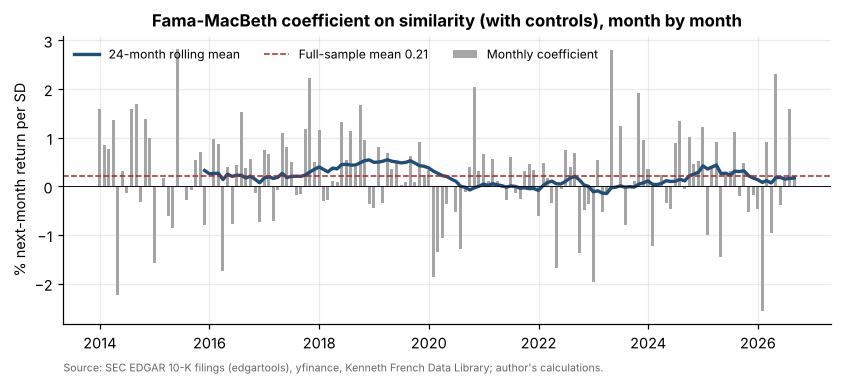

In [17]:
# Month-by-month standardised similarity coefficient of specification (2), and its 24-month rolling mean
mc = []
for t, g in PP.groupby("date"):
    g = g.dropna(subset=SPECS["(2) + controls"] + ["ret_next"])
    if len(g) < 30:
        continue
    X = g[SPECS["(2) + controls"]]; X = (X - X.mean()) / X.std()
    mc.append((t, sm.OLS(g["ret_next"] * 100, sm.add_constant(X)).fit().params["sim_combined"]))
FMM = pd.Series(dict(mc))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(FMM.index, FMM, width=20, color=PALETTE[7], label="Monthly coefficient")
ax.plot(FMM.rolling(24).mean(), color=PALETTE[0], lw=2.2, label="24-month rolling mean")
ax.axhline(FMM.mean(), color="#B22222", ls="--", lw=1, label=f"Full-sample mean {FMM.mean():.2f}")
ax.axhline(0, color="black", lw=0.6); ax.set_ylabel("% next-month return per SD")
ax.set_title("Fama-MacBeth coefficient on similarity (with controls), month by month"); ax.legend(fontsize=8, ncol=3, loc="upper left")
source(ax, SRC)
fig.savefig(FIG / "fig_fm_rolling.png"); plt.show()

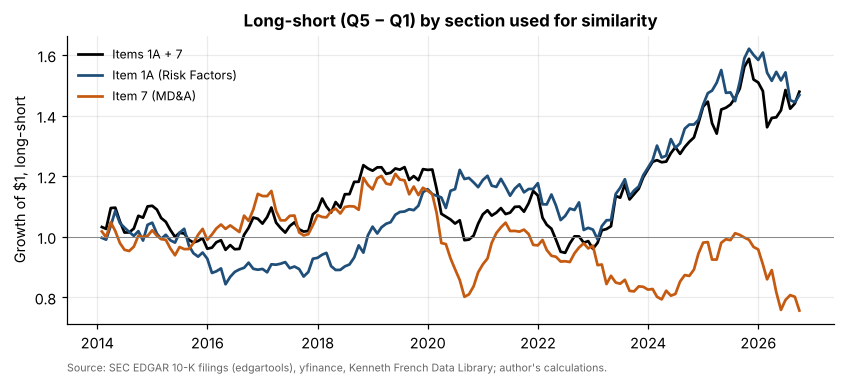

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for k, lab, c in [("sim_combined", "Items 1A + 7", "black"), ("sim_1a", "Item 1A (Risk Factors)", PALETTE[0]), ("sim_7", "Item 7 (MD&A)", PALETTE[1])]:
    ax.plot((1 + Q[k].loc[START:END, "Q5-Q1"]).cumprod(), color=c, lw=1.8, label=lab)
ax.axhline(1, color="grey", lw=0.6); ax.set_ylabel("Growth of $1, long-short")
ax.set_title("Long-short (Q5 − Q1) by section used for similarity"); ax.legend(fontsize=8, loc="upper left")
source(ax, SRC)
fig.savefig(FIG / "fig_sections.png"); plt.show()

## 5. Do sentiment measures sort returns on their own?

In [19]:
SENT = {}
for k, lab in [("d_lm_negative", "Δ LM negative share (Q5 = biggest increase)"), ("finbert_mda", "FinBERT MD&A tone (Q5 = most positive)"),
               ("d_finbert", "Δ FinBERT tone (Q5 = biggest improvement)")]:
    qq = quintile_returns(P, k).loc[START:END]
    SENT[lab] = stats(qq["Q5-Q1"])
SENTT = pd.DataFrame(SENT).T
SENTT[["Mean (monthly)", "t(mean)", "Alpha FF5+Mom (monthly)", "t(alpha)"]].round(4)

,Mean (monthly),t(mean),Alpha FF5+Mom (monthly),t(alpha)
Δ LM negative share (Q5 = biggest increase),0.0017,0.6217,0.0023,1.1303
FinBERT MD&A tone (Q5 = most positive),0.0009,0.2928,0.0003,0.1145
Δ FinBERT tone (Q5 = biggest improvement),0.0006,0.2215,-0.0005,-0.2391


## 6. Largest changers and comparison with the paper

In [20]:
TOPCH = V.nsmallest(10, "sim_combined")[["ticker", "fy", "filed", "sim_1a", "sim_7", "sim_combined"]]
TOPCH

,ticker,fy,filed,sim_1a,sim_7,sim_combined
86,AMAT,2023,2023-12-15,0.783582,0.843102,0.792162
1212,TMUS,2013,2014-02-25,0.866819,0.804755,0.826307
1155,SCHW,2017,2018-02-22,0.660451,0.885773,0.828189
445,DELL,2021,2021-03-26,0.504720,0.965392,0.844242
536,GE,2016,2017-02-24,0.504272,0.900798,0.864236
541,GE,2021,2022-02-11,0.958587,0.861395,0.881983
995,NVDA,2012,2012-03-13,0.643146,0.976492,0.891854
887,MO,2022,2023-02-27,0.844768,0.896614,0.892548
939,MU,2014,2014-10-27,0.920466,0.880790,0.899200
1096,PM,2018,2019-02-07,0.980769,0.889068,0.901921


In [21]:
# Cohen, Malloy and Nguyen (2020), NBER WP 25084 (Mar 2019 revision), Table I Panel A/B, Table II Panel A/B (Sim_Cosine) and Table IV column (2).
PAPER = {"Sample": "All US firms with 10-K/10-Q text, 1995–2014", "Documents": "86,965 10-Ks + 258,271 10-Qs",
         "Text": "Full 10-K and 10-Q", "Holding": "Enter the month after filing, hold 3 months",
         "Factor model for alpha": "Market, size, value, momentum, liquidity",
         "Median cosine similarity": "0.947", "EW Q5−Q1 excess return (monthly)": "0.31% (t = 3.13)",
         "EW Q5−Q1 alpha (monthly)": "0.32% (t = 4.21)", "VW Q5−Q1 alpha (monthly)": "0.34% (t = 2.53)",
         "Fama-MacBeth coefficient on similarity (with controls)": "0.31 (t = 2.51)",
         "Same, per one standard deviation of similarity": "≈0.06% a month (0.31 × SD 0.191)"}
fmr = FM_RAW["(2) + controls"][0].loc["sim_combined"]
OURS = {"Sample": f"Current S&P 100 ({V['ticker'].nunique()} firms with usable pairs), returns Jan 2014 – Sep 2026",
        "Documents": f"{len(F[F['fy'] >= 2012])} original 10-Ks (FY2012–2025)",
        "Text": "Item 1A + Item 7 of the 10-K", "Holding": "Most recent 10-K signal, re-ranked monthly",
        "Factor model for alpha": "Fama-French 5 + momentum",
        "Median cosine similarity": f"{V['sim_combined'].median():.3f}",
        "EW Q5−Q1 excess return (monthly)": f"{MAIN['Mean (monthly)'] * 100:.2f}% (t = {MAIN['t(mean)']:.2f})",
        "EW Q5−Q1 alpha (monthly)": f"{MAIN['Alpha FF5+Mom (monthly)'] * 100:.2f}% (t = {MAIN['t(alpha)']:.2f})",
        "VW Q5−Q1 alpha (monthly)": f"{ROB['sim_combined · value-weight']['Alpha FF5+Mom (monthly)'] * 100:.2f}% (t = {ROB['sim_combined · value-weight']['t(alpha)']:.2f})",
        "Fama-MacBeth coefficient on similarity (with controls)": f"{fmr['coef']:.2f} (t = {fmr['t']:.2f})",
        "Same, per one standard deviation of similarity": f"{FM_STD['(2) + controls'][0].loc['sim_combined', 'coef']:.2f}% a month (t = {FM_STD['(2) + controls'][0].loc['sim_combined', 't']:.2f})"}
COMP = pd.DataFrame({"Cohen, Malloy & Nguyen (2020)": PAPER, "This replication": OURS})
COMP

,"Cohen, Malloy & Nguyen (2020)",This replication
Sample,"All US firms with 10-K/10-Q text, 1995–2014","Current S&P 100 (94 firms with usable pairs), ..."
Documents,"86,965 10-Ks + 258,271 10-Qs",1313 original 10-Ks (FY2012–2025)
Text,Full 10-K and 10-Q,Item 1A + Item 7 of the 10-K
Holding,"Enter the month after filing, hold 3 months","Most recent 10-K signal, re-ranked monthly"
Factor model for alpha,"Market, size, value, momentum, liquidity",Fama-French 5 + momentum
Median cosine similarity,0.947,0.985
EW Q5−Q1 excess return (monthly),0.31% (t = 3.13),0.29% (t = 1.26)
EW Q5−Q1 alpha (monthly),0.32% (t = 4.21),0.20% (t = 0.84)
VW Q5−Q1 alpha (monthly),0.34% (t = 2.53),-0.33% (t = -1.23)
Fama-MacBeth coefficient on similarity (with controls),0.31 (t = 2.51),10.85 (t = 2.64)


## Save

In [22]:
cov.to_csv(DATA / "coverage.csv"); SRC_COUNTS.to_csv(DATA / "section_sources.csv")
DESC.to_csv(DATA / "descriptives.csv"); CORR.to_csv(DATA / "correlations.csv")
P.to_csv(DATA / "panel_monthly.csv", index=False)
for k, q_ in Q.items():
    q_.to_csv(DATA / f"quintile_returns_{k}.csv")
QVW.to_csv(DATA / "quintile_returns_sim_combined_vw.csv")
QTAB.to_csv(DATA / "quintile_stats.csv"); ROBT.to_csv(DATA / "robustness.csv"); SENTT.to_csv(DATA / "sentiment_sorts.csv")
FMT_RAW.to_csv(DATA / "fama_macbeth_raw.csv"); FMT_STD.to_csv(DATA / "fama_macbeth_std.csv")
TOPCH.to_csv(DATA / "largest_changers.csv", index=False); CHARS.to_csv(DATA / "quintile_characteristics.csv"); FMM.to_csv(DATA / "fama_macbeth_monthly_sim.csv")
YEARLY.to_csv(DATA / "yearly_spread.csv"); WINT.to_csv(DATA / "event_time_windows.csv"); CAR.to_csv(DATA / "event_time_car.csv"); COMP.to_csv(DATA / "comparison_with_paper.csv")
json.dump({k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in MAIN.items()},
          open(DATA / "main_result.json", "w"), indent=2)